# Código TP4: Métodos Supervisados Avanzados

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

# https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
from sklearn.naive_bayes import MultinomialNB

# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.RadiusNeighborsClassifier.html
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier

# https://xgboost.readthedocs.io/en/stable/python/python_api.html
from xgboost import XGBClassifier  # Tiene interfaz estilo sklearn

# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
from sklearn.ensemble import RandomForestClassifier

# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html
from sklearn.svm import SVC, SVR  # Clasificación / Regresión

# Ej 1
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

# Ej 2
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances


## Carga de Datasets

News Groups Dataset: https://scikit-learn.org/stable/datasets/real_world.html#newsgroups-dataset

In [30]:
X, y = fetch_20newsgroups(subset="train",return_X_y=True, remove=("headers",))
X_train, X_val, y_train, y_val = train_test_split(X, y,test_size=0.25, random_state=1)
X_test, y_test = fetch_20newsgroups(subset="test",return_X_y=True,remove=("headers",))

print('Sample X: ', X_train[0])
print('Sample y: ', y_train[0])

topics = fetch_20newsgroups(subset="train").target_names
print(topics) 

Sample X:  |> In article <1993Apr5.220457.6800@spdc.ti.com> dwhite@epcot.spdc.ti.com (Dan White) writes:
|> 
|> >However, haven't we already lost our right to bear arms?
|> 
|> >	It seems that in most states, like Texas, a citizen may own a
|> >gun and carry while at his home or business.  But a citizen is severely
|> >restricted from bearing outside these areas.  Here in Texas you cannot
|> >carry in your car except when "traveling" which is usually defined as
|> >"traveling across a county line."  How did this come about?  Are there
|> >any court rulings on the legality of restricting the carrying of a
|> >weapon outside the home?  
|> 

In Texas, it is legal to carry handguns while "traveling", and also to and from
sporting activities.           ^^^^^^^^

Chapter 46 of the Texas State Penal Code does NOT restrict long guns.
Therefore, it is legal to carry and transport long guns any place in Texas.

Regards,
Clay


Sample y:  16
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.m

In [31]:
# spirals (los CSV no tienen encabezado)
esp_train = pd.read_csv("esp_train.csv", sep=',', header=None)
print(esp_train)
esp_test = pd.read_csv("esp_test.csv", sep=',', header=None)
print(esp_test)

# spirals con dos variables de ruido uniforme
esp_4d_train = pd.read_csv("esp_4d_train_noisy.csv", sep=',', header=None)
print(esp_4d_train)
esp_4d_test = pd.read_csv("esp_4d_test_noisy.csv", sep=',', header=None)
print(esp_4d_test)

# diagonals
diag_train = pd.read_csv("diag_train.csv", sep=',')
print(diag_train)
diag_test = pd.read_csv("diag_test.csv", sep=',')
print(diag_test)

# RRL
RRL = pd.read_csv("RRL.csv", sep=',')
print(RRL)

# Lampone
Lampone = pd.read_csv("Lampone.csv", sep=',')
print(Lampone)

            0         1  2
0   -0.932861 -0.348555  0
1    0.471330 -0.152117  0
2   -0.676675 -0.456844  0
3   -0.337246 -0.237882  0
4   -0.750397 -0.383328  0
..        ...       ... ..
995 -0.506005 -0.375704  1
996  0.909315 -0.083658  1
997  0.924952  0.271076  1
998 -0.397196  0.515772  1
999  0.244938  0.218105  1

[1000 rows x 3 columns]
             0         1  2
0     0.395183 -0.838678  0
1    -0.257198 -0.813991  0
2    -0.811248  0.288827  0
3    -0.970632  0.123704  0
4     0.285026  0.602301  0
...        ...       ... ..
3995  0.597976 -0.580146  1
3996 -0.659446 -0.309822  1
3997 -0.502408 -0.467037  1
3998  0.015358 -0.081344  1
3999 -0.796823  0.591190  1

[4000 rows x 3 columns]
            0         1         2         3  4
0    0.285859  0.795249  0.646488 -0.217658  0
1    0.556382  0.482016  0.098951 -0.749375  0
2    0.250219 -0.372066 -0.284810  0.407843  0
3   -0.812271  0.326447 -0.842205 -0.487461  0
4   -0.856101 -0.420801  0.226435  0.571628  0
..      

## Ejercicio 1: Naïve-Bayes

Vectorizamos, contando las veces que ocurre cada palabra de un diccionario dado en cada texto

In [32]:
largo_diccionario=4000
vec = CountVectorizer(stop_words='english',max_features=largo_diccionario)
Xvec_train = vec.fit_transform(X_train).toarray()
Xvec_test = vec.transform(X_test).toarray()
Xvec_val = vec.transform(X_val).toarray()

print('Sample X: ', Xvec_train[0], ' | non-zero: ', Xvec_train[0][Xvec_train[0] != 0])
print('Sample y: ', y_train[0])

Sample X:  [0 0 0 ... 0 0 0]  | non-zero:  [1 1 1 1 1 1 1 1 1 4 1 1 2 1 2 1 1 1 1 1 1 1 1 2 1 1 2 2 1 1 2 1 2 1 1 1 1
 1 5 2 1 1 1 1]
Sample y:  16


Y lo clasificamos con el clasificador discreto multinomial (pag. 180 del libro de Mitchell)


Mejor combinación en validación: dict=4000, alfa=0.1
error_train    0.1355
error_val      0.2319
error_test     0.2943


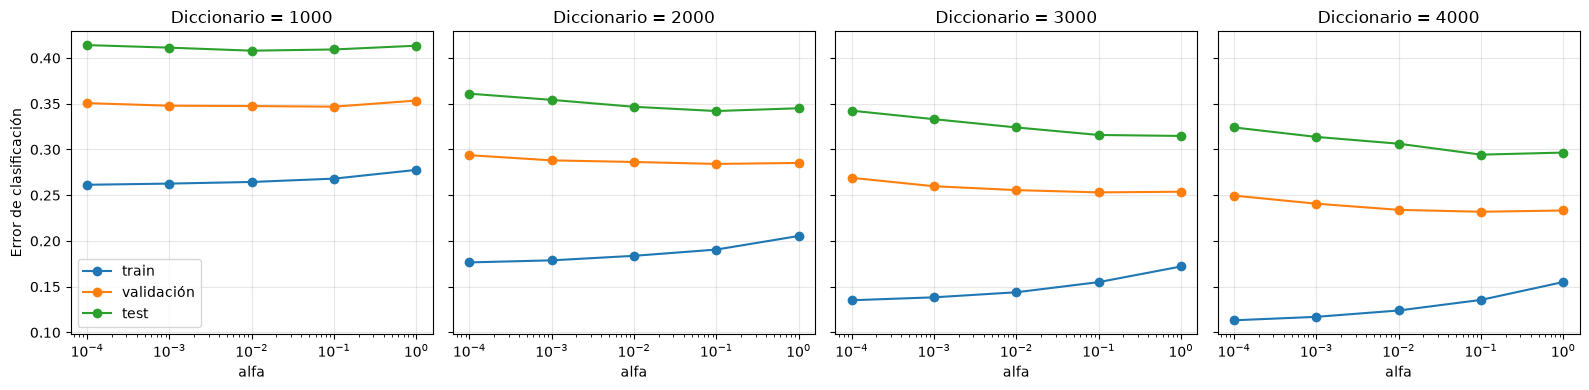

Error en test del modelo elegido: 0.2943


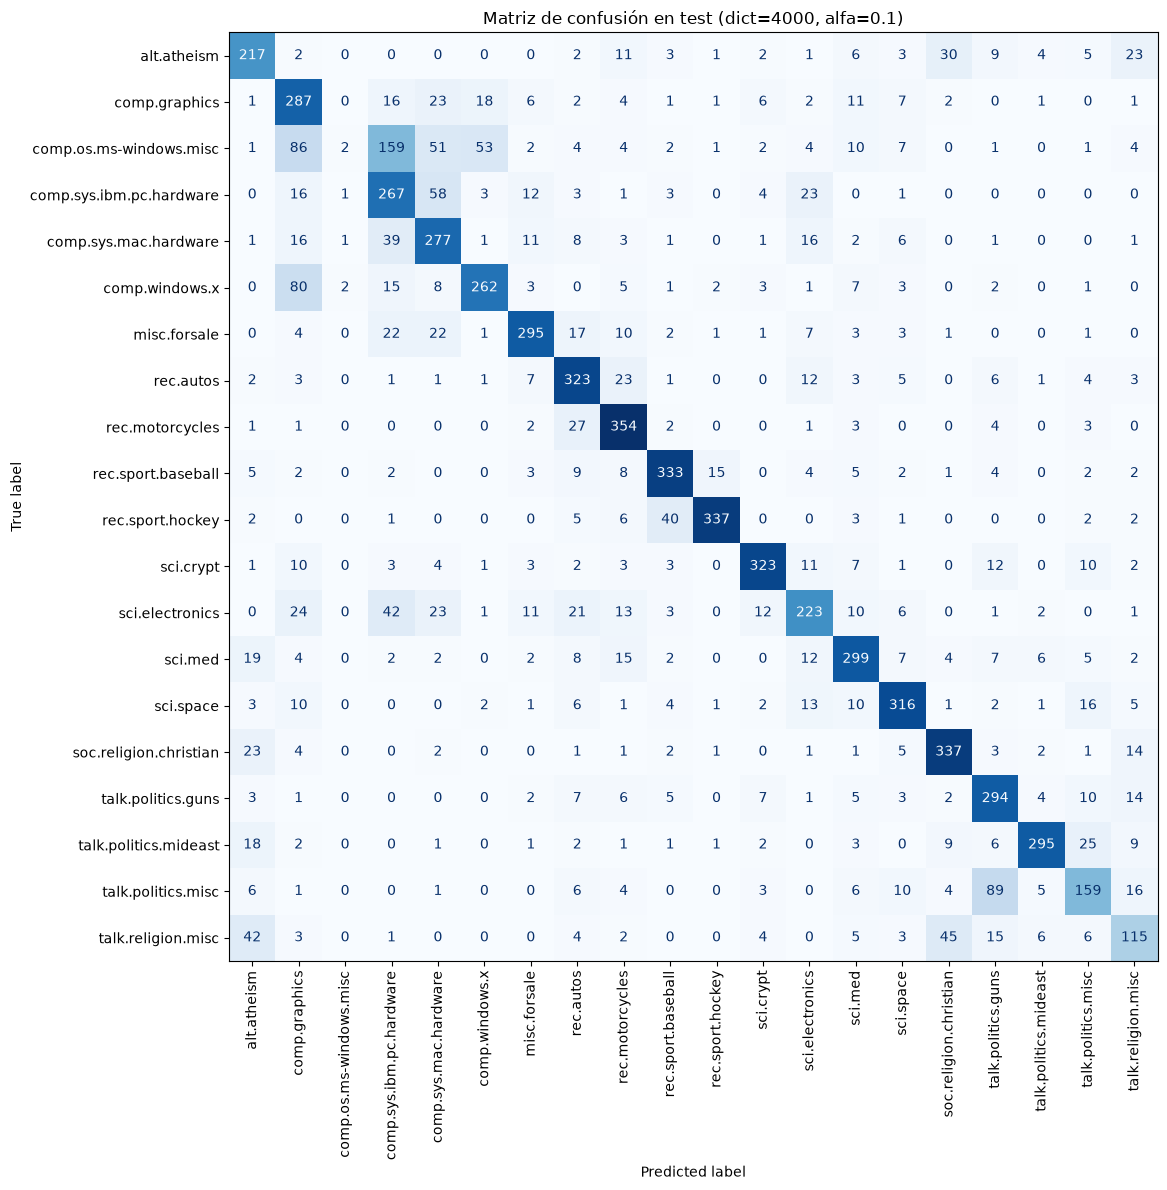

In [33]:
# Búsqueda en grilla: largo del diccionario x alfa
largos = [1000, 2000, 3000, 4000]
alfas = [1, 0.1, 0.01, 0.001, 0.0001]

resultados = []
for largo in largos:
    # El diccionario se aprende solo con train y cambia con cada largo
    vec_g = CountVectorizer(stop_words='english', max_features=largo)
    Xg_train = vec_g.fit_transform(X_train)
    Xg_val = vec_g.transform(X_val)
    Xg_test = vec_g.transform(X_test)

    for alfa in alfas:
        modelo = MultinomialNB(alpha=alfa).fit(Xg_train, y_train)
        resultados.append({
            'largo': largo,
            'alfa': alfa,
            'error_train': 1 - modelo.score(Xg_train, y_train),
            'error_val': 1 - modelo.score(Xg_val, y_val),
            'error_test': 1 - modelo.score(Xg_test, y_test),
        })

resultados = pd.DataFrame(resultados)

# La selección usa únicamente el error de validación
mejor = resultados.loc[resultados['error_val'].idxmin()]
mejor_largo, mejor_alfa = int(mejor['largo']), mejor['alfa']
print(f'\nMejor combinación en validación: dict={mejor_largo}, alfa={mejor_alfa}')
print(mejor[['error_train', 'error_val', 'error_test']].round(4).to_string())

# Curvas de error vs alfa para cada largo de diccionario
fig, axes = plt.subplots(1, len(largos), figsize=(16, 4), sharey=True)
for ax, largo in zip(axes, largos):
    sub = resultados[resultados['largo'] == largo]
    for columna, nombre in [('error_train', 'train'), ('error_val', 'validación'), ('error_test', 'test')]:
        ax.plot(sub['alfa'], sub[columna], marker='o', label=nombre)
    ax.set_xscale('log')
    ax.set_title(f'Diccionario = {largo}')
    ax.set_xlabel('alfa')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Error de clasificación')
axes[0].legend()
plt.tight_layout()
plt.show()

# Reentrenamos el modelo elegido y calculamos la matriz de confusión en test
vec_mejor = CountVectorizer(stop_words='english', max_features=mejor_largo)
Xm_train = vec_mejor.fit_transform(X_train)
Xm_test = vec_mejor.transform(X_test)
nb_mejor = MultinomialNB(alpha=mejor_alfa).fit(Xm_train, y_train)
y_pred = nb_mejor.predict(Xm_test)
print(f'Error en test del modelo elegido: {1 - accuracy_score(y_test, y_pred):.4f}')

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=topics, xticks_rotation=90,
    cmap='Blues', colorbar=False, ax=ax
)
ax.set_title(f'Matriz de confusión en test (dict={mejor_largo}, alfa={mejor_alfa})')
plt.tight_layout()
plt.show()


El parámetro alfa controla el suavizado que se aplica a los conteos que usa el modelo para estmiar las probabilidades. Se utiliza para evitar que una palabra que nunca apareció en una clase durante el entrenamiento tenga probabilidad 0 en el modelo.
Puede verse en el gráfico de los errores de clasificación como el error de entrenamiento aumenta a medida que aumenta el alfa, mientras que el error de validación es más alto para alfas mas chicos en diccionarios más grandes. Esto indica un poco de sobreajuste para valores chicos de alfa. Con diccionarios más grandes, al no realizarse el suavizado, el modelo ajusta a las palabras con las que realiza el entrenamiento, y esto hace que cuando se aplica el mismo modelo a artículos con palabras que no estuvieron en el entrenamiento, se producen estos casos en los que una palabra que nunca apareció hace que la clase tenga probabilidad 0. 

Con respecto al tamaño del diccionario puede verse una diferencia mas evidente, en la cuál los errores de entrenamiento y validación se reducen a medida que el tamaño del diccionario aumenta. Esto puede deberse a que, al ser 20 temas diferentes, el abanico de palabras necesario para reconocerlos es mayor.

También podemos ver que el comportamiento de validación es practicamente igual al de test, solo que con un error más bajo. Esto tiene sentido, ya que los datos del conjunto de validación se obtuvieron del mismo conjunto que el de entrenamiento. El comportarse de la misma forma hace el conjunto de validación sea útil para ajustar el alfa.

Generando la matriz de confusión con el modelo generado con el mejor alfa y vectorizando con el diccionario más largo, puede verse que el modelo realiza una buena predicción de los temas de las noticias. Podemos notar que la mayoría de las predicciones errónas suceden con los temas similares, como la alta predicción de "talks.politics.guns" cuando el tema real es "talks.politics.misc".

## Ejercicio 2: K-NN

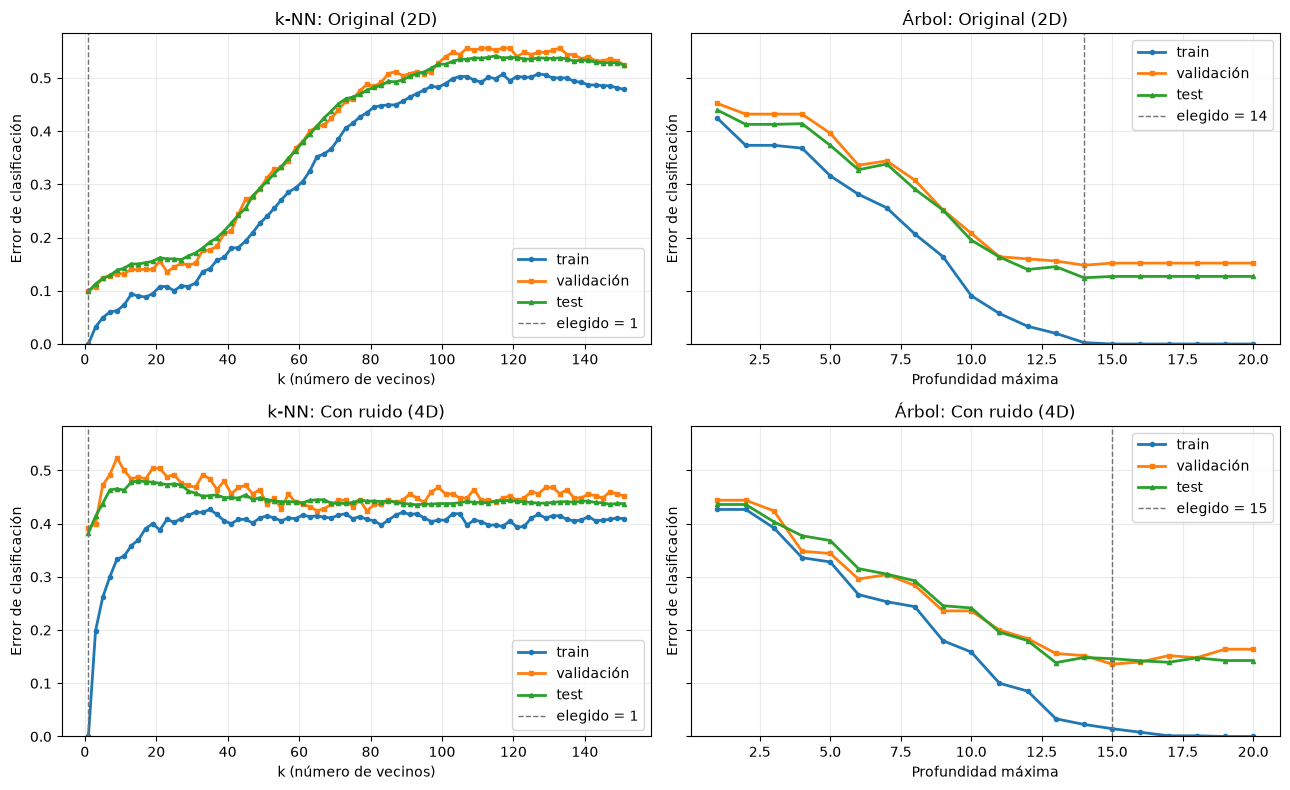

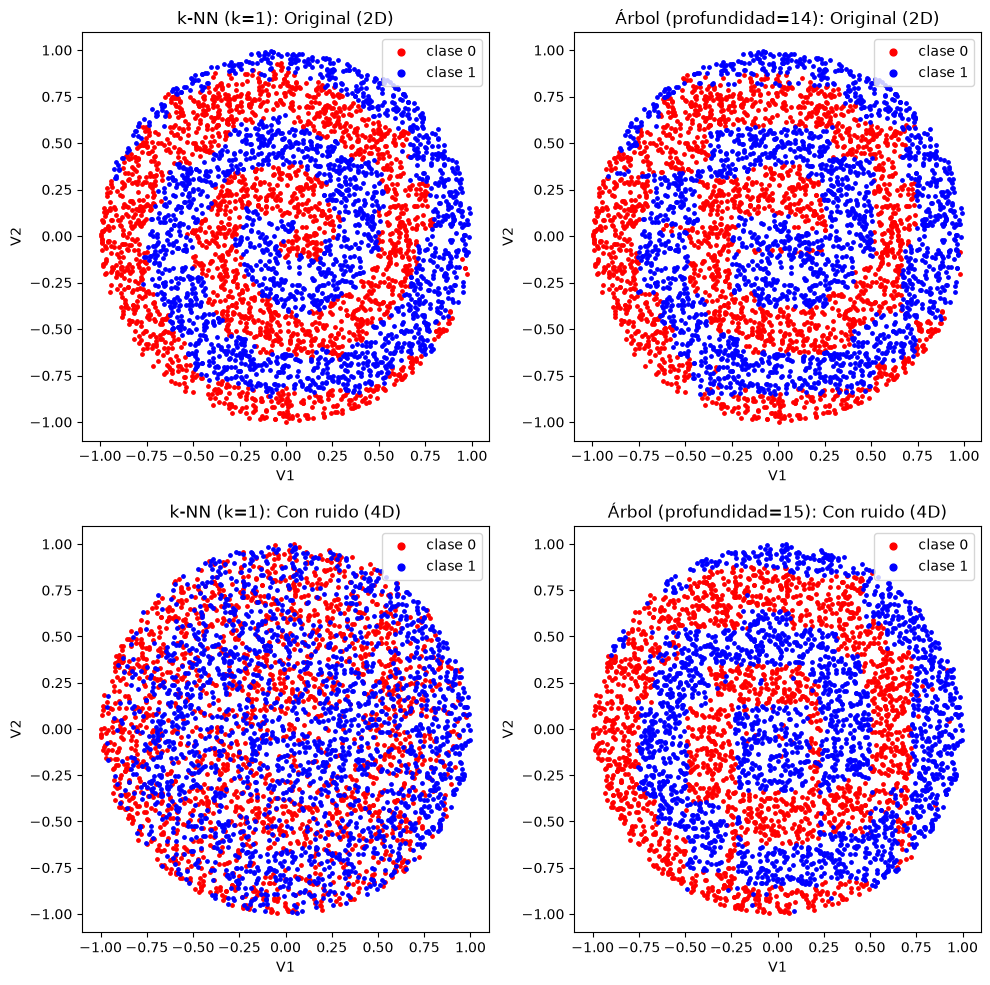

In [44]:

datos_esp = {
    'Original (2D)': (esp_train.to_numpy(), esp_test.to_numpy()),
    'Con ruido (4D)': (esp_4d_train.to_numpy(), esp_4d_test.to_numpy()),
}

# Separa train en ajuste (75%) y validación (25%), y devuelve también test
def separar(train, test):
    X, y = train[:, :-1], train[:, -1].astype(int)
    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)
    return X_tr, y_tr, X_val, y_val, test[:, :-1], test[:, -1].astype(int)


# Calcula el error de train, validación y test para cada valor del parámetro
def barrido(crear_modelo, valores, X_tr, y_tr, X_val, y_val, X_te, y_te):
    filas = []
    for valor in valores:
        modelo = crear_modelo(valor).fit(X_tr, y_tr)
        filas.append({
            'valor': valor,
            'error_train': 1 - modelo.score(X_tr, y_tr),
            'error_val': 1 - modelo.score(X_val, y_val),
            'error_test': 1 - modelo.score(X_te, y_te),
        })
    return pd.DataFrame(filas)


# Grafica las curvas de error y marca el valor elegido por validación
def graficar_errores(ax, tabla, titulo, xlabel, log=False):
    ax.plot(tabla['valor'], tabla['error_train'],  lw=2, marker='o', ms=3, label='train')
    ax.plot(tabla['valor'], tabla['error_val'],  lw=2, marker='s', ms=3, label='validación')
    ax.plot(tabla['valor'], tabla['error_test'],  lw=2, marker='^', ms=3, label='test')
    mejor = tabla.loc[tabla['error_val'].idxmin(), 'valor']
    ax.axvline(mejor, color='0.45', ls='--', lw=1, label=f'elegido = {mejor:.3g}')
    if log:
        ax.set_xscale('log')
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Error de clasificación')
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()


# Grafica las predicciones sobre test en las dos primeras variables
def graficar_predicciones(ax, X_te, y_pred, titulo):
    for clase, color in {0:'red', 1:'blue'}.items():
        ax.scatter(*X_te[y_pred == clase, :2].T, s=6, color=color, label=f'clase {clase}')
    ax.set_title(titulo)
    ax.set_xlabel('V1')
    ax.set_ylabel('V2')
    ax.set_aspect('equal')
    ax.legend(loc='upper right', markerscale=2)


valores_k = list(range(1, 152, 2))  # impares: evitan empates entre las dos clases
valores_prof = list(range(1, 21))

tablas_knn, tablas_arbol, finales = {}, {}, {}
for nombre, (train, test) in datos_esp.items():
    X_tr, y_tr, X_val, y_val, X_te, y_te = separar(train, test)

    tablas_knn[nombre] = barrido(lambda k: KNeighborsClassifier(n_neighbors=k),
                                 valores_k, X_tr, y_tr, X_val, y_val, X_te, y_te)
    tablas_arbol[nombre] = barrido(lambda p: DecisionTreeClassifier(max_depth=p, random_state=1),
                                   valores_prof, X_tr, y_tr, X_val, y_val, X_te, y_te)

    mejor_k = int(tablas_knn[nombre].loc[tablas_knn[nombre]['error_val'].idxmin(), 'valor'])
    mejor_p = int(tablas_arbol[nombre].loc[tablas_arbol[nombre]['error_val'].idxmin(), 'valor'])
    finales[nombre] = {
        'k-NN': (f'k={mejor_k}', KNeighborsClassifier(n_neighbors=mejor_k).fit(X_tr, y_tr)),
        'Árbol': (f'profundidad={mejor_p}', DecisionTreeClassifier(max_depth=mejor_p, random_state=1).fit(X_tr, y_tr)),
    }

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for fila, nombre in zip(axes, datos_esp):
    graficar_errores(fila[0], tablas_knn[nombre], f'k-NN: {nombre}', 'k (número de vecinos)')
    graficar_errores(fila[1], tablas_arbol[nombre], f'Árbol: {nombre}', 'Profundidad máxima')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for fila, (nombre, (train, test)) in zip(axes, datos_esp.items()):
    X_te = test[:, :-1]
    for ax, (metodo, (param, modelo)) in zip(fila, finales[nombre].items()):
        graficar_predicciones(ax, X_te, modelo.predict(X_te), f'{metodo} ({param}): {nombre}')
plt.tight_layout()
plt.show()

Se utilizó un conjunto de validación del 25% del conjunto de entrenamiento original. En base a los resultados sobre este conjunto se eligieron los mejores parámetros para el modelo, el cuál se entrenó con el 75% restante de los datos.

En el caso de las espirales originales, el error de entrenamiento de k-nn con k=1 es 0, mientras que el de validación y test es de 0.9. Esto sucede porque durante el entrenamiento, el punto mas cercano de cada candidato es si mismo. Por lo que siempre toma la clase correcta. En el caso de validación y test, este error aumenta un poco, ya que el mismo punto que se busca no se encuentra en los datos de entrenamiento, por lo que busca al mas cercano. Y al buscarlo, si el punto cuya clase se está buscando se encuentra en los bordes de la espiral, el más cercano puede ser uno de la espiral opuesta, generando el error que se ve en el gráfico.

En el caso de la espiral con ruido, vemos como el error de entrenamiento se mantiene en 0 por el mismo motivo, pero el de validación y test es mucho mayor, casi cercano al azar. Esto sucede porque los datos cuentan con 4 dimensiones, de las cuales solo 2 aportan información. Esto hace que cuando se busca la distancia de un punto en las 4 dimensiones, el ruido influya mucho en la decision de la clase, haciendo que el modelo tenga un desempeño considerablemente peor.

En comparación, vemos que los árboles casi no presentan cambios entre los datos originales y los datos con ruido. Esto pasa porque el árbol elige las dimensiones sobre las cuales hace los cortes, por lo que prioriza las que tienen más información, ignorando así las dimensiones con ruido.

Original (2D): D entre 0.031 y 0.893; elegido D=0.114 
Con ruido (4D): D entre 0.230 y 1.430; elegido D=0.319 


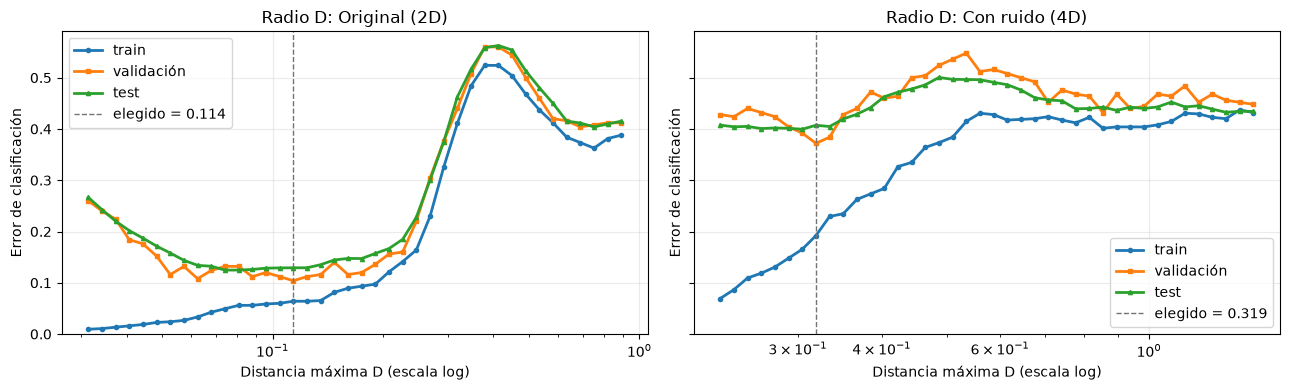

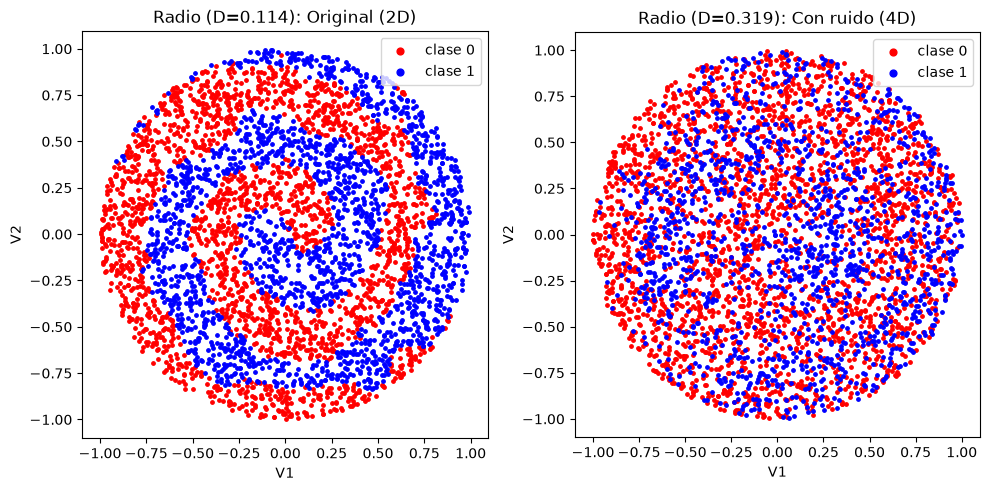

In [ ]:
N_CANDIDATOS = 40


# Sacamos la lista de candidatos segun las distancias entre los puntos en train.
def candidatos_D(X_tr):
    dist_vecino = NearestNeighbors(n_neighbors=2).fit(X_tr).kneighbors(X_tr)[0][:, 1]
    d_min = np.median(dist_vecino)
    d_max = np.median(pairwise_distances(X_tr))
    return np.geomspace(d_min, d_max, N_CANDIDATOS), d_min, d_max


# Un punto sin vecinos dentro de D recibe la clase más frecuente de train
def crear_rnn(D):
    return RadiusNeighborsClassifier(radius=D, outlier_label='most_frequent')

tablas_rnn = {}
for nombre, (train, test) in datos_esp.items():
    X_tr, y_tr, X_val, y_val, X_te, y_te = separar(train, test)
    valores_D, d_min, d_max = candidatos_D(X_tr)
    tabla = barrido(crear_rnn, valores_D, X_tr, y_tr, X_val, y_val, X_te, y_te)
    tablas_rnn[nombre] = tabla

    mejor_D = tabla.loc[tabla['error_val'].idxmin(), 'valor']
    finales[nombre]['Radio'] = (f'D={mejor_D:.3f}', crear_rnn(mejor_D).fit(X_tr, y_tr))
    print(f'{nombre}: D entre {d_min:.3f} y {d_max:.3f}; elegido D={mejor_D:.3f} ')

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (nombre, tabla) in zip(axes, tablas_rnn.items()):
    graficar_errores(ax, tabla, f'Radio D: {nombre}', 'Distancia máxima D (escala log)', log=True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (nombre, (train, test)) in zip(axes, datos_esp.items()):
    X_te = test[:, :-1]
    param, modelo = finales[nombre]['Radio']
    graficar_predicciones(ax, X_te, modelo.predict(X_te), f'Radio ({param}): {nombre}')
plt.tight_layout()
plt.show()


Para obtener el rago de búsqueda del parámetro D, analizamos las distancias entre puntos en el conjunto de entrenamiento para obtener una distancia mínima y una distancia máxima sobre las cuales hacer el análisis. Con esto, obtenemos el rango [0.03, 0.89] para el dataset original, y [0.23, 1.43] para el dataset con ruido. 

Haciendo el análisis del modelo en el dataset original variando D vemos que el mejor desempeño se da con D=0.114. Con este parámetro obtenemos un error de 0.1 en validación, de forma muy similar a lo que se veía eligiendo k=1. Y de la misma forma, a medida que aumenta la distancia, aumenta el error. Esto tiene sentido, ya que al aumentar la distancia, aumenta la cantidad de vecinos cercanos que se toman en cuenta para la votación de la clase. En particular, se ve que al aumentar D lo suficiente, los resultados son aún peor que el azar. Esto sucede porque dicha distancia alcanza el siguiente brazo de la espiral, añadiendo a la votación aún más puntos de la clase errónea.

Para el caso del dataset con ruido, se ve un patrón similar al que se vió al aplicar k-nn variando la k. Se obtiene el mejor resultado con un D=0.319, pero el error de validación es de 0.4, lo cuál es muy cercano al azar. Esto nos dice que independientemente del modo en que se planteen los vecinos de k-nn, este algoritmo no logra resolver bien el problema de las espirales con ruido, dado que no puede quitarle importancia a las dimensiones que no aportan información. 

## Ejercicio 3: Boosting

### Ejemplo de boosting con XGBoost sobre espirales

In [37]:
esp_train_np = esp_train.to_numpy()

xgb_nrounds = 500  # total de árboles por ciclo
xgb_eta = 0.1      # learning rate (similar a redes neuronales)
xgb_maxdepth = 3   # profundidad máx de los árboles == complejidad

X = esp_train_np[:, 0:2]
y = esp_train_np[:, 2]

xgb = XGBClassifier(
    objective='binary:hinge', n_estimators=xgb_nrounds,
    learning_rate=xgb_eta, max_depth=xgb_maxdepth, colsample_bytree=1, verbosity=0,
    subsample=1)
xgb.fit(X, y, verbose=0)

xgb.score(X,y)

0.923

In [38]:
# COMPLETAR

## Ejercicio 4: Random Forests

In [39]:
rf_estimators = 1000
rf_mtry = 0

rf = RandomForestClassifier(
    n_estimators=rf_estimators,
    max_features=rf_mtry,
    bootstrap=True,
    class_weight='balanced',
    oob_score=True
)

# 1 - random_forest.oob_score_ := final out-of-bag error

# COMPLETAR

## Ejercicio 5: SVM

In [40]:
svm_kernel = 'rbf'  # 'rbf' / 'poly'
svm_C = 1.0
svm_gamma = 0.001
svm_degree = 3  # poly only, ignored otherwise

svm = SVC(
    C=svm_C,
    kernel=svm_kernel,
    gamma=svm_gamma,
    degree=svm_degree
)

# COMPLETAR